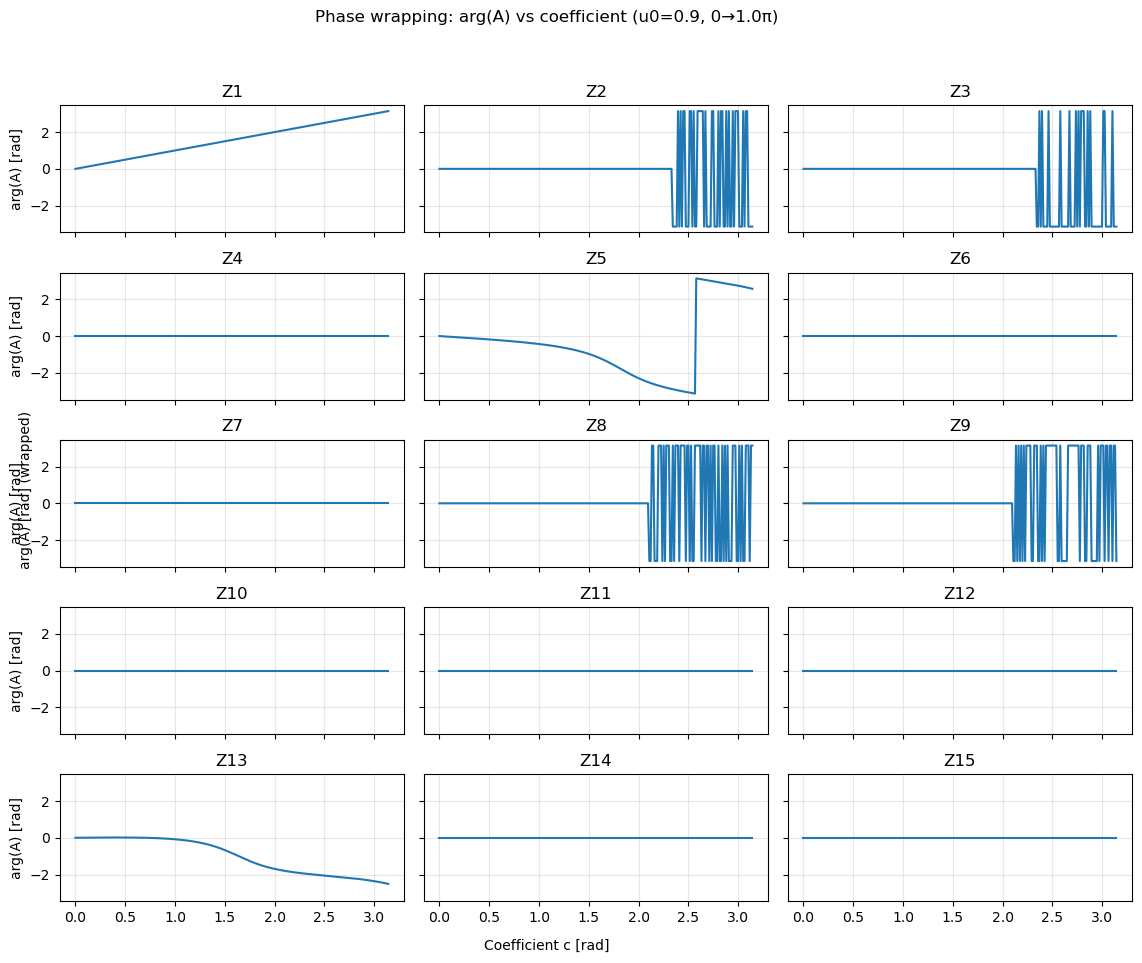

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from typing import Union
import math

# ---------------- helpers ----------------
def _to_knn(arr: np.ndarray) -> np.ndarray:
    """Coerce arr to (K,N,N). Accepts (K,N,N),(N,N,K),(N,K,N),(N,N)."""
    if arr.ndim == 2:
        return arr[None, ...].astype(np.float64)
    if arr.ndim != 3:
        raise ValueError(f"Unsupported rank {arr.ndim}")
    s0, s1, s2 = arr.shape
    if s1 == s2 and s0 != s1:        # (K,N,N)
        out = arr
    elif s0 == s1 and s0 != s2:      # (N,N,K)
        out = np.moveaxis(arr, -1, 0)
    elif s0 == s2 and s0 != s1:      # (N,K,N)
        out = np.moveaxis(arr, 1, 0)
    else:
        k_axis = int(np.argmin([s0, s1, s2]))
        out = arr if k_axis == 0 else np.moveaxis(arr, k_axis, 0)
        K, N1, N2 = out.shape
        if N1 != N2:
            raise ValueError(f"Cannot coerce {arr.shape} to (K,N,N)")
    return out.astype(np.float64)

def load_zernike_stack(path: Union[str, Path]) -> np.ndarray:  # <-- Py 3.8 friendly
    return _to_knn(np.load(path))

def unit_disk_grid(n: int):
    xs = (np.arange(n) - (n - 1) / 2.0) * (2.0 / n)
    ys = (np.arange(n) - (n - 1) / 2.0) * (2.0 / n)
    X, Y = np.meshgrid(xs, ys, indexing="xy")
    R = np.sqrt(X**2 + Y**2)
    mask = R <= 1.0 + 1e-12
    dA = (2.0 / n) ** 2
    return R, mask, dA

def gaussian_on_pupil(R, mask, u0: float):
    M = np.zeros_like(R, dtype=np.float64)
    M[mask] = np.exp(-(R[mask] ** 2) / (u0 ** 2))
    return M

# ---- fast sweep for one mode using incremental update over c ----
def argA_vs_coeff_for_mode(mode2d, R, mask, dA, u0, c_min, c_max, num):
    """
    Returns c_vals, argA (wrapped to [-pi,pi]) for one Zernike mode.
    Exact normalized overlap on the sampled grid; no small-phase approx.
    """
    M = gaussian_on_pupil(R, mask, u0)
    m = mode2d[mask]                 # (Nmask,)
    w = M[mask]                      # (Nmask,)
    norm_E = math.sqrt(m.size * dA)  # |exp(i phi)|=1 on mask
    norm_M = math.sqrt(np.sum(w**2) * dA)

    c_vals = np.linspace(c_min, c_max, num, dtype=np.float64)
    argA = np.empty_like(c_vals)

    # Start at c=0: E = 1
    E = np.ones_like(m, dtype=np.complex128)

    if num == 0:
        return c_vals, argA

    # At c0: (should be 0) but handle general case
    c0 = c_vals[0]
    if c0 != 0.0:
        E = np.exp(1j * (c0 * m))
    num0 = np.sum(E * w) * dA
    A0 = num0 / (norm_E * norm_M) if norm_M else 0.0 + 0.0j
    argA[0] = np.angle(A0)

    if num > 1:
        dc = c_vals[1] - c_vals[0]            # uniform step
        q = np.exp(1j * (dc * m))             # per-pixel increment
        for k in range(1, num):
            E *= q                             # E(c_k) = E(c_{k-1}) * exp(i dc m)
            numk = np.sum(E * w) * dA
            Ak = numk / (norm_E * norm_M) if norm_M else 0.0 + 0.0j
            argA[k] = np.angle(Ak)

    return c_vals, argA

# ---------------- main plotting routine ----------------
def plot_phase_wrapping(
    zernike_path="newzernike_stack.npy",
    Ksel=15,
    u0=0.90,
    coeff_max=1*np.pi,
    num=241,
    downsample=1,
    save_path=None,
    unwrap_overlay=False,
):
    """
    For Z1..Z_{Ksel}, sweep coefficient c from 0 to coeff_max and plot arg(A)(c).
    Set unwrap_overlay=True to overlay an unwrapped phase (faint).
    """
    Z = load_zernike_stack(zernike_path)      # (K,N,N) coerced
    K, N, _ = Z.shape
    Ksel = min(Ksel, K)
    Z = Z[:Ksel, ::downsample, ::downsample]
    _, Nds, _ = Z.shape

    R, mask, dA = unit_disk_grid(Nds)

    fig, axes = plt.subplots(5, 3, figsize=(12, 10), sharex=True, sharey=True)
    axes = axes.ravel()

    for k in range(Ksel):
        ax = axes[k]
        c, th = argA_vs_coeff_for_mode(Z[k], R, mask, dA, u0, 0.0, coeff_max, num)
        ax.plot(c, th)
        if unwrap_overlay:
            ax.plot(c, np.unwrap(th), alpha=0.35)  # optional overlay
        ax.set_title(f"Z{k+1}")
        ax.grid(True, alpha=0.3)
        if k % 3 == 0:
            ax.set_ylabel("arg(A) [rad]")

    # Turn off any extra subplots
    for ax in axes[Ksel:]:
        ax.axis("off")

    fig.suptitle(f"Phase wrapping: arg(A) vs coefficient (u0={u0}, 0→{coeff_max/np.pi:.1f}π)", y=0.98)
    fig.text(0.5, 0.04, "Coefficient c [rad]", ha="center")
    fig.text(0.06, 0.5, "arg(A) [rad] (wrapped)", va="center", rotation="vertical")

    plt.tight_layout(rect=[0.04, 0.05, 1, 0.95])
    if save_path:
        fig.savefig(save_path, dpi=150)
    plt.show()

# --------- example call ----------
# Adjust the path/params as needed:
# - Set downsample=2 or 4 to speed up on huge pupils; keep 1 for max fidelity.
# - Set unwrap_overlay=True to also show an unwrapped curve (faint).
path_candidates = ["newzernike_stack.npy", "newzernike.npy"]
zpath = next((p for p in path_candidates if Path(p).exists()), path_candidates[0])

plot_phase_wrapping(
    zernike_path=zpath,
    Ksel=15,
    u0=0.9,
    coeff_max=1*np.pi,
    num=241,          # increase to 401+ for denser curves (slower)
    downsample=1,     # set to 2 or 4 to speed up
    save_path=None,
    unwrap_overlay=False,
)


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from typing import Union
import math
# ---------- labels -----------
# --- Zernike labels for Noll indices 1..15 ---
ZERN_INFO = [
    dict(n=0, m=0,  expr=r"1",                          name="Piston"),
    dict(n=1, m=-1, expr=r"r\sin(\theta)",              name="Tilt Y"),
    dict(n=1, m=1,  expr=r"r\cos(\theta)",              name="Tilt X"),
    dict(n=2, m=-2, expr=r"r^{2}\sin(2\theta)",         name="45 Astigmatism"),
    dict(n=2, m=0,  expr=r"2r^{2}-1",                   name="Defocus"),
    dict(n=2, m=2,  expr=r"r^{2}\cos(2\theta)",         name="0 Astigmatism"),
    dict(n=3, m=-3, expr=r"r^{3}\sin(3\theta)",         name="Trefoil Y"),
    dict(n=3, m=-1, expr=r"(3r^{3}-2r)\sin(\theta)",    name="Y Coma"),
    dict(n=3, m=1,  expr=r"(3r^{3}-2r)\cos(\theta)",    name="X Coma"),
    dict(n=3, m=3,  expr=r"r^{3}\cos(3\theta)",         name="Trefoil X"),
    dict(n=4, m=-4, expr=r"r^{4}\sin(4\theta)",         name="Tetrafoil Y"),
    dict(n=4, m=-2, expr=r"(4r^{4}-3r^{2})\sin(2\theta)", name="Secondary Astigmatism Y"),
    dict(n=4, m=0,  expr=r"6r^{4}-6r^{2}+1",            name="3rd Order Spherical"),
    dict(n=4, m=2,  expr=r"(4r^{4}-3r^{2})\cos(2\theta)", name="Secondary Astigmatism X"),
    dict(n=4, m=4,  expr=r"r^{4}\cos(4\theta)",         name="Tetrafoil X"),
]

def zern_label(j: int, style: str = "short") -> str:
    """
    j: Noll index starting at 1
    style: 'short' -> 'Piston'; 'long' -> '$Z_n^m(r,\\theta)=...$ — Name'
    """
    z = ZERN_INFO[j-1]
    if style == "short":
        return f"{z['name']}"
    return rf"$Z_{{{z['n']}}}^{{{z['m']}}}(r,\theta)={z['expr']}$ — {z['name']}"
# --- helpers (same as before) ---
def _to_knn(arr: np.ndarray) -> np.ndarray:
    if arr.ndim == 2: return arr[None, ...].astype(np.float64)
    if arr.ndim != 3: raise ValueError(f"Unsupported rank {arr.ndim}")
    s0,s1,s2 = arr.shape
    if s1==s2 and s0!=s1: out = arr
    elif s0==s1 and s0!=s2: out = np.moveaxis(arr,-1,0)
    elif s0==s2 and s0!=s1: out = np.moveaxis(arr,1,0)
    else:
        k_axis = int(np.argmin([s0,s1,s2]))
        out = arr if k_axis==0 else np.moveaxis(arr,k_axis,0)
        K,N1,N2 = out.shape
        if N1!=N2: raise ValueError(f"Cannot coerce {arr.shape} to (K,N,N)")
    return out.astype(np.float64)

def load_zernike_stack(path: Union[str, Path]) -> np.ndarray:
    return _to_knn(np.load(path))

def unit_disk_grid(n: int):
    xs = (np.arange(n) - (n - 1)/2.0) * (2.0/n)
    ys = (np.arange(n) - (n - 1)/2.0) * (2.0/n)
    X, Y = np.meshgrid(xs, ys, indexing="xy")
    R = np.sqrt(X**2 + Y**2)
    mask = R <= 1.0 + 1e-12
    dA = (2.0/n)**2
    return R, mask, dA

def gaussian_on_pupil(R, mask, u0: float):
    M = np.zeros_like(R, dtype=np.float64)
    M[mask] = np.exp(-(R[mask]**2) / (u0**2))
    return M

def phase_and_intensity_vs_coeff(mode2d, R, mask, dA, u0, c_vals):
    M = gaussian_on_pupil(R, mask, u0)
    m = mode2d[mask]; w = M[mask]
    norm_E = math.sqrt(m.size * dA)
    norm_M = math.sqrt(np.sum(w**2) * dA)
    th = np.empty_like(c_vals); I = np.empty_like(c_vals)
    E = np.ones_like(m, dtype=np.complex128)
    c0 = float(c_vals[0])
    if c0 != 0.0: E = np.exp(1j * (c0 * m))
    A = (np.sum(E*w)*dA)/(norm_E*norm_M) if norm_M else 0j
    th[0] = np.angle(A); I[0] = float(np.abs(A)**2)
    if len(c_vals) > 1:
        dc = float(c_vals[1]-c_vals[0]); q = np.exp(1j*(dc*m))
        for k in range(1, len(c_vals)):
            E *= q
            A = (np.sum(E*w)*dA)/(norm_E*norm_M) if norm_M else 0j
            th[k] = np.angle(A); I[k] = float(np.abs(A)**2)
    return th, I
    
from matplotlib.ticker import FixedLocator, FuncFormatter, MultipleLocator

# π tick helpers for arg(A)
_PI_MAJOR = np.array([-np.pi, -np.pi/2, 0.0, np.pi/2, np.pi])

def _pi_formatter():
    lab = {
        -np.pi:  r"$-\pi$",
        -np.pi/2: r"$-\frac{\pi}{2}$",
        0.0:     r"$0$",
        np.pi/2: r"$\frac{\pi}{2}$",
        np.pi:   r"$\pi$",
    }
    return FuncFormatter(lambda val, pos: lab.get(
        _PI_MAJOR[np.argmin(np.abs(_PI_MAJOR - val))] if np.min(np.abs(_PI_MAJOR - val)) < 1e-6 else val,
        rf"${val/np.pi:.2g}\pi$"  # fallback if limits change
    ))

def apply_pi_ticks(ax):
    """Set y-ticks at [-π, -π/2, 0, π/2, π] and format labels in terms of π."""
    ax.set_ylim(-np.pi, np.pi)
    ax.yaxis.set_major_locator(FixedLocator(_PI_MAJOR))
    ax.yaxis.set_major_formatter(_pi_formatter())

def _fmt_pi_major(x, pos):
    k = int(np.round(x/np.pi))
    if abs(x/np.pi - k) > 1e-6:
        return ""  # only label exact multiples of π
    if k == 0: return r"$0$"
    s = "-" if k < 0 else ""
    kabs = abs(k)
    if kabs == 1:
        return rf"${s}\pi$"
    return rf"${s}{kabs}\pi$"

def apply_pi_xticks(ax, max_mult=4, show_minors=True):
    """Major ticks at integer multiples of π from -max_multπ..+max_multπ."""
    ax.set_xlim(-max_mult*np.pi, max_mult*np.pi)
    ax.xaxis.set_major_locator(MultipleLocator(base=np.pi))
    ax.xaxis.set_major_formatter(FuncFormatter(_fmt_pi_major))
    if show_minors:
        ax.xaxis.set_minor_locator(MultipleLocator(base=np.pi/2))
#plot_phase_and_intensity_consistent(zernike_path="newzernike_stack.npy", u0=0.9, coeff_max=4*np.pi,Imin=1e-14, num=4*241, downsample=1)

In [3]:
def plot_phase_and_intensity_neat(
    zernike_path="fixedzernike_stack.npy",
    Ksel=15,
    u0=0.30,
    coeff_max=10*np.pi,
    num=401,                 # odd -> includes 0 exactly
    downsample=1,
    Imin=1e-14,
    titles=None,
    figsize=(12, 9),
    header_heights=(0.12, 0.10),    # (title_row_height, legend_row_height)
    hspace=0.30, wspace=0.20
):
    
    # ---- data prep ----
    Z = load_zernike_stack(zernike_path)
    K, N, _ = Z.shape
    Ksel = min(Ksel, K)
    Z = Z[:Ksel, ::downsample, ::downsample]
    _, Nds, _ = Z.shape
    R, mask, dA = unit_disk_grid(Nds)

    # symmetric coefficient sweep
    c_vals = np.linspace(-coeff_max, coeff_max, num, dtype=np.float64)

    # ---- figure with a dedicated 2-row header (title + legend) ----
    import matplotlib.pyplot as plt
    from matplotlib.gridspec import GridSpec
    plt.rcParams.update({'font.size': 10})
    plt.rc('axes', titlesize=18)
    plt.rc('axes', labelsize=16) 
    
    nrows, ncols = 5, 3
    mid_row = nrows // 2
    mid_col = ncols // 2

    fig = plt.figure(figsize=figsize)
    gs = GridSpec(
        nrows + 2, ncols, figure=fig,
        height_ratios=[header_heights[0], header_heights[1]] + [1]*nrows,
        hspace=hspace, wspace=wspace
    )

    # header axes
    title_ax  = fig.add_subplot(gs[0, :]); title_ax.axis("off")
    legend_ax = fig.add_subplot(gs[1, :]); legend_ax.axis("off")

    # data axes (5x3)
    axes = []
    for r in range(nrows):
        for c in range(ncols):
            ax = fig.add_subplot(gs[r+2, c])
            axes.append(ax)

    # same x limits for all (acts like shared x)
    for ax in axes:
        ax.set_xlim(c_vals[0], c_vals[-1])

    phase_handle = intensity_handle = None

    # ---- plot each mode ----
    for k in range(Ksel):
        ax = axes[k]
        th, I = phase_and_intensity_vs_coeff(Z[k], R, mask, dA, u0, c_vals)
        th_masked = np.where(I > Imin, th, np.nan)

        # Left axis: arg(A)
        h1, = ax.plot(c_vals, th_masked, label="arg(A)")
        ax.set_ylim(-np.pi, np.pi)
        apply_pi_ticks(ax)  
        ax.grid(True, alpha=0.3)

        # Right axis: |A|^2 (orange)
        ax2 = ax.twinx()
        h2, = ax2.plot(c_vals, I, color="orange", label="|A|²")
        ax2.set_ylim(0, 1)

        row, col = divmod(k, ncols)
        if col != ncols - 1:
            ax2.spines["right"].set_visible(False)
            ax2.tick_params(right=False, labelright=False)

        # Titles
        if titles and k < len(titles):
            ax.set_title(titles[k], fontsize=9)
        else:
            ax.set_title(f"Z{k+1}: {zern_label(k+1, 'short')}", size=10)
        
        # De-duplicate tick labels
        if row < nrows - 1: ax.tick_params(labelbottom=False)
        if col > 0:         ax.tick_params(labelleft=False)

        # One-time axis labels (middle-left/right + bottom-center)
        if col == 0 and row == mid_row:
            ax.set_ylabel("arg(A) [rad]")
        if col == ncols - 1 and row == mid_row:
            ax2.set_ylabel("|A|²")
        if row == nrows - 1 and col == mid_col:
            ax.set_xlabel("Zernike Coefficient a [rad]")
        for ax in axes:
            apply_pi_xticks(ax, max_mult=int(round(coeff_max/np.pi)), show_minors=True)
        if phase_handle is None:
            phase_handle, intensity_handle = h1, h2
        
    # blank any unused panels
    for k in range(Ksel, nrows*ncols):
        axes[k].axis("off")

    # ---- header content: title on its own row, legend on its own row ----
    title_str = "Phase & Intensity vs Zernike Coefficient a"
    # put title near the TOP of the title row
    title_ax.text(0.5, 0.98, title_str, ha="center", va="top", transform=title_ax.transAxes, size=18)

    # center the legend in the legend row (well below the title)
    legend_ax.legend([phase_handle, intensity_handle], ["arg(A)", "|A|²"],
                     loc="center", ncol=2, frameon=False)

    # margins
    fig.subplots_adjust(left=0.08, right=0.95, bottom=0.08, top=0.98)
    plt.savefig('ZernikePhaseWrapping.pdf', dpi=300)
    plt.show()

In [5]:
%matplotlib inline

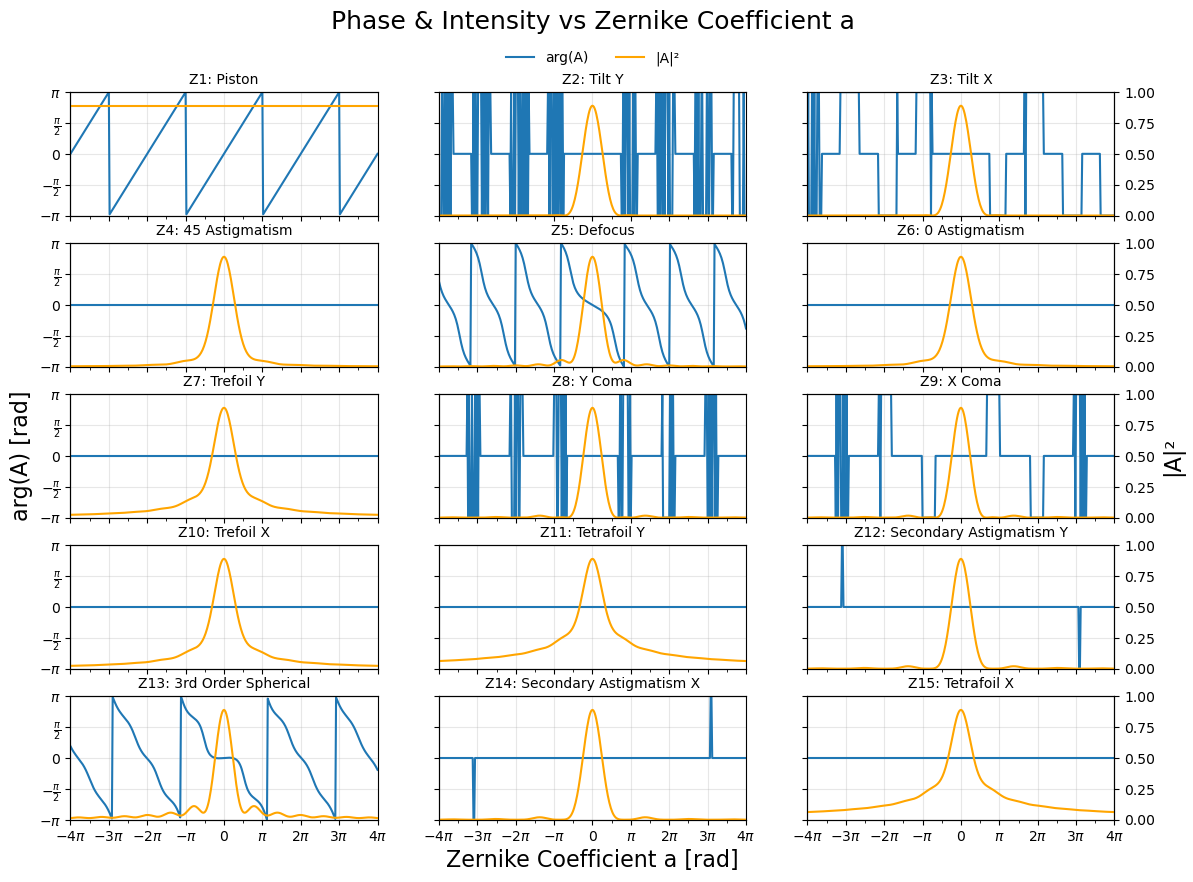

In [7]:
plot_phase_and_intensity_neat(
    zernike_path="fixedzernike_stack.npy",
    Ksel=15,
    u0=0.90,
    coeff_max=4*np.pi,     # now plots from -coeff_max to +coeff_max
    num=401,                # odd count puts c=0 exactly in the grid
    downsample=1,
    Imin=4.677290533825251e-29,
    titles=None
)

In [30]:
def _A_from_phase_intensity(th: np.ndarray, I: np.ndarray) -> np.ndarray:
    """Reconstruct complex A from phase and intensity arrays."""
    return np.sqrt(np.maximum(I, 0.0)) * np.exp(1j * th)

def _order_from_three_levels(A1: np.ndarray, A2: np.ndarray, A4: np.ndarray, r12: float, r24: float) -> float:
    """
    Estimate convergence order p from three grids:
    A1 = fine (f=1), A2 = f=2, A4 = f=4. r12 = 2, r24 = 2 (step ratios).
    Uses median over c to be robust; clamps to [0.8, 2.2].
    """
    d12 = np.abs(A1 - A2)
    d24 = np.abs(A2 - A4)
    eps = 1e-15
    valid = (d12 > eps) & (d24 > eps)
    if np.any(valid):
        p_c = np.log(d24[valid] / d12[valid]) / np.log(r24)  # expect ~1 for edge-limited, ~2 if perfectly smooth
        p = float(np.median(p_c))
        return float(np.clip(p, 0.8, 2.2))
    return 1.0  # conservative default

def estimate_riemann_error_for_mode(
    mode2d_full: np.ndarray,
    u0: float,
    coeff_max: float = 4*np.pi,
    num: int = 121,
    downsamples: tuple = (1, 2, 4),
    Imin: float = 0.0,
    p_override: float = None,
) -> dict:
    """
    Estimate discretization (Riemann-sum) error for a single Zernike mode by
    comparing grids at downsample factors in `downsamples` (subset of {1,2,4}).
    Returns a dict with c-grid, A_fine, A_extrap, and absolute/relative errors.

    Parameters
    ----------
    mode2d_full : 2D numpy array at highest available resolution (N x N)
    u0          : Gaussian width parameter (your sim's u0)
    coeff_max   : sweep half-span; we evaluate c in [-coeff_max, +coeff_max]
    num         : number of coefficient samples (odd recommended, includes 0)
    downsamples : grid factors; include 1 (fine) and at least one coarser (2 or 4)
    Imin        : mask threshold; when |A|^2 < Imin, relative errors are suppressed
    p_override  : if given, use this order (e.g. 1.0) instead of auto-estimation

    Returns
    -------
    {
      "c": c_vals,
      "A_fine": complex ndarray,
      "A_extrap": complex ndarray,
      "abs_err_A": ndarray,
      "rel_err_A": ndarray,           # masked when |A| < sqrt(Imin)
      "abs_err_mag": ndarray,         # for |A|
      "rel_err_mag": ndarray,         # masked when |A| < sqrt(Imin)
      "abs_err_I": ndarray,           # for |A|^2
      "rel_err_I": ndarray,           # masked when |A|^2 < Imin
      "p_used": float,                # order actually used
      "have_levels": tuple            # the factors actually computed
    }
    """
    # Build coefficient grid
    c_vals = np.linspace(-coeff_max, coeff_max, num, dtype=np.float64)

    # Helper: evaluate A(c) on a given downsample factor f
    def eval_on_factor(f: int) -> np.ndarray:
        md = mode2d_full[::f, ::f]
        N = md.shape[0]
        R, mask, dA = unit_disk_grid(N)
        th, I = phase_and_intensity_vs_coeff(md, R, mask, dA, u0, c_vals)
        # Optional: when coupling is extremely small, phase is undefined; still reconstruct A for diffs
        A = _A_from_phase_intensity(th, I)
        return A

    # Compute available levels
    factors = tuple(sorted(set(downsamples)))
    if 1 not in factors:
        raise ValueError("Include downsample factor 1 in `downsamples` to treat it as the fine grid.")
    A_levels = {f: eval_on_factor(f) for f in factors}
    A1 = A_levels[1]

    # Pick order p
    if p_override is not None:
        p_used = float(p_override)
    else:
        if 2 in A_levels and 4 in A_levels:
            p_used = _order_from_three_levels(A_levels[1], A_levels[2], A_levels[4], r12=2.0, r24=2.0)
        elif 2 in A_levels:
            # With two levels, assume p=1 (edge-limited) unless you want to pass p_override
            p_used = 1.0
        else:
            # Only one level available → cannot estimate
            raise ValueError("Need at least two grid levels (e.g. downsamples=(1,2)) to estimate an error.")
    # Choose the coarser level to pair with fine for Richardson
    if 2 in A_levels:
        f_coarse = 2
    else:
        # fallback: take the largest factor available (other than 1)
        others = [f for f in factors if f != 1]
        f_coarse = max(others)

    A2 = A_levels[f_coarse]
    r = float(f_coarse)  # step ratio

    # Richardson extrapolation to infinite resolution:
    # A* ≈ A1 + (A1 - A2)/(r^p - 1)
    denom = (r**p_used - 1.0)
    # guard tiny denominator (should not happen for r>1)
    denom = denom if abs(denom) > 1e-12 else 1e-12
    A_extrap = A1 + (A1 - A2) / denom

    # Errors
    abs_err_A  = np.abs(A_extrap - A1)
    mag1       = np.abs(A1)
    I1         = mag1**2

    with np.errstate(divide="ignore", invalid="ignore"):
        rel_err_A   = np.where(mag1 > np.sqrt(Imin), abs_err_A / mag1, np.nan)
        abs_err_mag = np.abs(np.abs(A_extrap) - mag1)
        rel_err_mag = np.where(mag1 > np.sqrt(Imin), abs_err_mag / mag1, np.nan)
        abs_err_I   = np.abs(np.abs(A_extrap)**2 - I1)
        rel_err_I   = np.where(I1 > Imin, abs_err_I / I1, np.nan)

    return dict(
        c=c_vals,
        A_fine=A1,
        A_extrap=A_extrap,
        abs_err_A=abs_err_A,
        rel_err_A=rel_err_A,
        abs_err_mag=abs_err_mag,
        rel_err_mag=rel_err_mag,
        abs_err_I=abs_err_I,
        rel_err_I=rel_err_I,
        p_used=float(p_used),
        have_levels=factors,
    )

In [33]:
# Example: estimate error for Z5 at your highest-resolution stack Z (K,N,N)
k = 4  # zero-based index => Z5
Z = load_zernike_stack("newzernike_stack.npy")
results = estimate_riemann_error_for_mode(
    mode2d_full=Z[k],    # pass the full-res 2D mode
    u0=0.90,
    coeff_max=4*np.pi,
    num=121,
    downsamples=(1,2,4), # needs at least (1,2); (1,2,4) yields auto p
    Imin=1e-14
)

print("Estimated order p:", results["p_used"])
print("Max abs error |A| :", np.nanmax(results["abs_err_mag"]))
print("Max rel error |A| :", np.nanmax(results["rel_err_mag"]))
print("Max rel error |A|^2:", np.nanmax(results["rel_err_I"]))

Estimated order p: 1.0087803539403866
Max abs error |A| : 0.0007366116370766396
Max rel error |A| : 0.0195350314347573
Max rel error |A|^2: 0.038688445416357686


In [35]:
def _overlap_A_sum_order(mode2d, R, mask, dA, u0, c, reverse=False):
    """
    Compute normalized overlap A(c) but control the accumulation order
    (forward vs reversed) to probe floating-point round-off.
    """
    M = gaussian_on_pupil(R, mask, u0)
    m = mode2d[mask]
    w = M[mask]
    E = np.exp(1j * (c * m))
    t = (E * w).astype(np.complex128)   # summands of the numerator (masked)

    if reverse:
        s = t[::-1].sum()
    else:
        s = t.sum()

    norm_E = math.sqrt(m.size * dA)           # |E|=1 on mask
    norm_M = math.sqrt(np.sum(w**2) * dA)
    A = (s * dA) / (norm_E * norm_M) if norm_M else 0.0 + 0.0j
    return A

def recommend_Imin_empirical(mode2d_full, u0, coeff_max=4*np.pi, num=121, safety=50):
    """
    Empirical noise floor from order-sensitivity.
    For each c in [-coeff_max,+coeff_max], compute A with forward and reversed
    summation order; the difference estimates round-off. Return a single Imin.

    Returns: Imin_emp (float), and a dict with details if you want to inspect.
    """
    c_vals = np.linspace(-coeff_max, coeff_max, num, dtype=np.float64)
    N = mode2d_full.shape[0]
    R, mask, dA = unit_disk_grid(N)

    dA_mag = np.empty_like(c_vals)
    for i, c in enumerate(c_vals):
        A_f = _overlap_A_sum_order(mode2d_full, R, mask, dA, u0, c, reverse=False)
        A_r = _overlap_A_sum_order(mode2d_full, R, mask, dA, u0, c, reverse=True)
        dA_mag[i] = np.abs(A_f - A_r)

    # Convert to intensity-scale floor and inflate by a safety factor
    I_noise = dA_mag**2
    # robust global threshold: use 99th percentile (or max) times safety
    base = np.percentile(I_noise, 99.0)
    Imin_emp = float(safety * max(base, 0.0))

    details = {"c": c_vals, "A_diff": dA_mag, "I_noise": I_noise}
    return Imin_emp, details

def recommend_Imin_theoretical(mode2d_full, u0, safety=10):
    """
    Theoretical absolute error bound for |A| from pairwise/blocked summation,
    converted to intensity and inflated by 'safety'. Fast and c-independent.

    Uses: err(sum) ≈ γ_eff * sum|t_k|  with γ_eff ~ u * (1 + log2(Nmask))
    where u ≈ 1.11e-16 is the unit roundoff for float64.
    """
    N = mode2d_full.shape[0]
    R, mask, dA = unit_disk_grid(N)
    M = gaussian_on_pupil(R, mask, u0)
    w = M[mask]

    Nmask = int(mask.sum())
    # unit roundoff (half of eps)
    u = 0.5 * np.finfo(np.float64).eps
    gamma_eff = u * (1.0 + np.log2(max(2, Nmask)))  # mild model for NumPy's pairwise sum

    sum_abs = np.sum(np.abs(w)) * dA                 # ∑|t_k|·ΔA (since |E|=1)
    norm_E = math.sqrt(Nmask * dA)
    norm_M = math.sqrt(np.sum(w**2) * dA)
    denom  = norm_E * norm_M if norm_M else 1.0

    abs_err_A = (gamma_eff * sum_abs) / denom        # absolute error in |A|
    Imin_th   = float(safety * abs_err_A**2)         # convert to intensity and inflate
    return Imin_th

In [37]:
# Choose some representative modes (e.g., the worst cases like coma/trefoil)
Z = load_zernike_stack("newzernike_stack.npy")
u0 = 0.90

# Pick one mode to set a global threshold (or take the max across a few)
k = 7  # e.g., Z8 (0-based index)
Imin_emp, info = recommend_Imin_empirical(Z[k], u0, coeff_max=4*np.pi, num=1601, safety=50)
Imin_th = recommend_Imin_theoretical(Z[k], u0, safety=10)

Imin = max(Imin_emp, Imin_th)
print("Recommended Imin =", Imin, "(empirical =", Imin_emp, ", theoretical =", Imin_th, ")")

Recommended Imin = 4.677290533825251e-29 (empirical = 1.302881544670689e-30 , theoretical = 4.677290533825251e-29 )
